## ECT完整实现


Duplicate key in file PosixPath('/home/ning/miniconda3/envs/zd/lib/python3.8/site-packages/matplotlib/mpl-data/matplotlibrc'), line 272 ('font.sans-serif: DejaVu Sans, Bitstream Vera Sans, Computer Modern Sans Serif, Lucida Grande, Verdana, Geneva, Lucid, Arial, Helvetica, Avant Garde, sans-serif')
Duplicate key in file PosixPath('/home/ning/miniconda3/envs/zd/lib/python3.8/site-packages/matplotlib/mpl-data/matplotlibrc'), line 413 ('axes.unicode_minus: True  # use Unicode for the minus symbol rather than hyphen.  See')


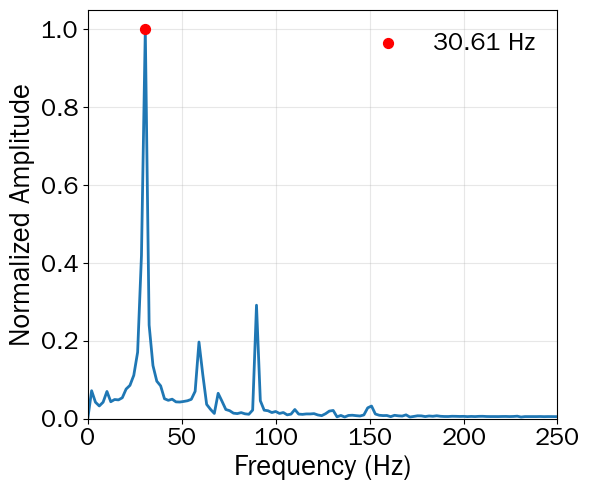

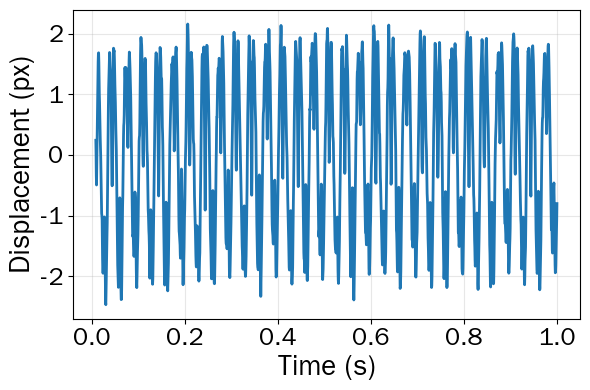

========== Centroid / ECT ==========
频谱主频：30.612245 Hz（图例 30.61 Hz）
最小位移：-2.472211 px
最大位移：2.161756 px
峰峰值：4.633967 px
振幅（峰峰值/2）：2.316983 px
Estimated Amplitude (px) : 2.317
输出目录：/home/ning/zd/results_111_two_methods


In [1]:
# ECT 完整独立实现
from pathlib import Path
import json
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from scipy.signal import hilbert
from IPython.display import display

root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p/"data/30hz-20.hdf5").exists()), None)
if root is None:
    raise FileNotFoundError("找不到data/30hz-20.hdf5")
data_path = root/"data/30hz-20.hdf5"
out_dir = root/"results_111_two_methods"
out_dir.mkdir(exist_ok=True)
roi = (100, 600, 420, 460)  # xmin, xmax, ymin, ymax，边界均包含

# 读取全部事件。
with h5py.File(data_path, "r") as handle:
    raw = handle["CD/events"][:]
all_x = raw["x"].astype(float)
all_y = raw["y"].astype(float)
all_t = raw["t"].astype(float)*1e-6

# 同一质心流程计算两套序列：
# 频谱使用0–0.5 s、dt=0.002 s；完整位移使用0–1 s、dt=0.0005 s。
series = {}
for series_name, time_range, dt in (
        ("spectrum", (0.0, 0.5), 0.002),
        ("displacement", (0.0, 1.0), 0.0005)):
    xmin, xmax, ymin, ymax = roi
    tmin, tmax = time_range
    selected = ((all_x >= xmin) & (all_x <= xmax) &
                (all_y >= ymin) & (all_y <= ymax) &
                (all_t >= tmin) & (all_t <= tmax))
    t = all_t[selected]
    y = all_y[selected]
    if len(t) == 0:
        raise ValueError(f"ECT {series_name}范围内没有事件")

    # 按时间窗建立纵向事件剖面，每窗至少50个事件。
    first_t, last_t = float(t.min()), float(t.max())
    local_y_min, local_y_max = int(y.min()), int(y.max())
    bin_count = int((last_t-first_t)//dt)
    frame_id = ((t-first_t)/dt).astype(np.int64)
    valid = (frame_id >= 0) & (frame_id < bin_count)
    frame_id = frame_id[valid]
    local_y = y[valid].astype(np.int64)-local_y_min
    counts = np.bincount(frame_id, minlength=bin_count)
    retained_bins = counts >= 50
    profiles = np.zeros((bin_count, local_y_max-local_y_min+1), dtype=float)
    np.add.at(profiles, (frame_id, local_y), 1.0)
    profiles = profiles[retained_bins]
    times = first_t+(np.flatnonzero(retained_bins)+0.5)*dt

    # 对每个纵向剖面做sigma=1空间平滑，再计算加权质心。
    coordinates = np.arange(profiles.shape[1], dtype=float)
    centers = np.empty(len(profiles), dtype=float)
    for index, profile in enumerate(profiles):
        smoothed_profile = gaussian_filter(profile, sigma=1.0)
        centers[index] = np.sum(coordinates*smoothed_profile)/(
            np.sum(smoothed_profile)+1e-9)
    centers -= np.mean(centers)

    # 质心序列再做sigma=1时间平滑；Hilbert相位频率只作为辅助量。
    signal = gaussian_filter(centers-np.mean(centers), sigma=1.0)
    analytic = hilbert(signal)
    phase = np.unwrap(np.angle(analytic))
    phase_frequency = float(np.median(
        np.diff(phase)/(2*np.pi*np.diff(times))))
    series[series_name] = {
        "times": times, "signal": signal,
        "phase_frequency_hz": phase_frequency, "dt": dt,
    }

short_times = series["spectrum"]["times"]
short_signal = series["spectrum"]["signal"]
full_times = series["displacement"]["times"]
displacement = series["displacement"]["signal"]

# 短序列频谱。
spectrum_dt = float(np.mean(np.diff(short_times)))
if not np.allclose(np.diff(short_times), spectrum_dt,
                   rtol=1e-5, atol=1e-10):
    raise ValueError("ECT短序列有效时间窗不连续，不能直接FFT")
frequencies = np.fft.rfftfreq(len(short_signal), d=spectrum_dt)
magnitude = np.abs(np.fft.rfft(short_signal-np.mean(short_signal)))
normalized_spectrum = magnitude/(np.max(magnitude)+1e-12)
peak_index = int(np.argmax(normalized_spectrum[1:])+1)
peak_hz = float(frequencies[peak_index])

# 完整位移FFT作为报告对照。
full_dt = float(np.mean(np.diff(full_times)))
if not np.allclose(np.diff(full_times), full_dt, rtol=1e-5, atol=1e-10):
    raise ValueError("ECT完整位移有效时间窗不连续，不能直接FFT")
full_frequencies = np.fft.rfftfreq(len(displacement), d=full_dt)
full_magnitude = np.abs(np.fft.rfft(displacement-np.mean(displacement)))
full_peak_index = int(np.argmax(full_magnitude[1:])+1)
full_peak_hz = float(full_frequencies[full_peak_index])

minimum = float(np.min(displacement))
maximum = float(np.max(displacement))
amplitude = float((maximum-minimum)/2)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(frequencies, normalized_spectrum, lw=2, color="tab:blue")
ax.scatter(peak_hz, normalized_spectrum[peak_index], c="red", s=50,
           zorder=3, label=f"{peak_hz:.2f} Hz")
ax.set_xlabel("Frequency (Hz)", fontsize=20)
ax.set_ylabel("Normalized Amplitude", fontsize=20)
ax.set_xlim(0, 250); ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3); ax.tick_params(axis="both", labelsize=18)
ax.legend(frameon=False, fontsize=18, loc="upper right")
fig.tight_layout()
spectrum_path = out_dir/"centroid_spectrum_30hz.png"
fig.savefig(spectrum_path, dpi=300, bbox_inches="tight")
display(fig); plt.close(fig)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(full_times, displacement, lw=2, color="tab:blue")
ax.set_xlabel("Time (s)", fontsize=20)
ax.set_ylabel("Displacement (px)", fontsize=20)
ax.grid(alpha=0.3); ax.tick_params(axis="both", labelsize=18)
fig.tight_layout()
displacement_path = out_dir/"centroid_displacement_30hz.png"
fig.savefig(displacement_path, dpi=300, bbox_inches="tight")
display(fig); plt.close(fig)

centroid_output = {
    "method": "Centroid", "data": str(data_path),
    "settings": {
        "spectrum_event_time_range_s": [0, 0.5],
        "spectrum_dt_s": 0.002,
        "displacement_event_time_range_s": [0, 1],
        "displacement_dt_s": 0.0005,
        "roi_xxyy": list(roi), "minimum_events": 50,
        "spatial_smoothing_sigma": 1.0,
        "temporal_smoothing_sigma": 1.0,
        "implementation": "Direct inline centroid implementation",
    },
    "spectrum_peak_hz": peak_hz,
    "spectrum_samples": int(len(short_signal)),
    "spectrum_dt_s": spectrum_dt,
    "spectrum_fft_duration_s": float(len(short_signal)*spectrum_dt),
    "spectrum_time_range_s": [float(short_times[0]), float(short_times[-1])],
    "displacement_samples": int(len(displacement)),
    "displacement_dt_s": full_dt,
    "displacement_time_range_s": [float(full_times[0]), float(full_times[-1])],
    "min_displacement_px": minimum, "max_displacement_px": maximum,
    "peak_to_peak_px": maximum-minimum, "amplitude_px": amplitude,
    "full_displacement_fft_peak_hz": full_peak_hz,
    "spectrum_window_amplitude_px": float(np.ptp(short_signal)/2),
}
np.savez_compressed(
    out_dir/"centroid_signals.npz", spectrum_times=short_times,
    spectrum_displacement_px=short_signal, freqs_hz=frequencies,
    normalized_spectrum=normalized_spectrum,
    displacement_times=full_times, displacement_px=displacement)
(out_dir/"centroid_summary.json").write_text(
    json.dumps(centroid_output, ensure_ascii=False, indent=2), encoding="utf-8")

print("========== Centroid / ECT ==========")
print(f"频谱主频：{peak_hz:.6f} Hz（图例 {peak_hz:.2f} Hz）")
print(f"最小位移：{minimum:.6f} px")
print(f"最大位移：{maximum:.6f} px")
print(f"峰峰值：{maximum-minimum:.6f} px")
print(f"振幅（峰峰值/2）：{amplitude:.6f} px")
print(f"Estimated Amplitude (px) : {amplitude:.3f}")
print(f"输出目录：{out_dir}")


## GPE完整实现


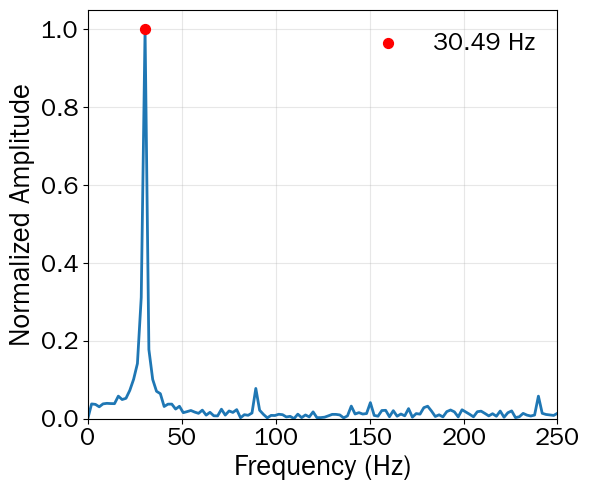

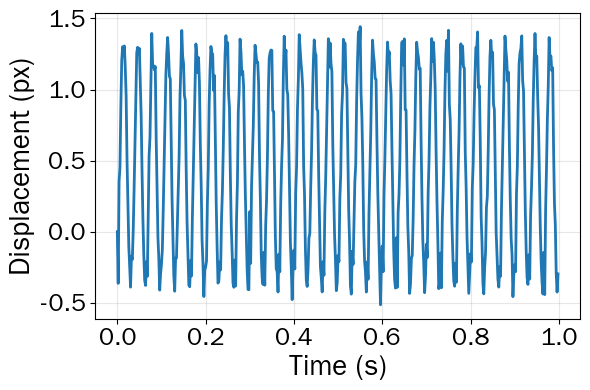

========== Gabor / GPE ==========
频谱主频：30.487805 Hz（图例 30.49 Hz）
最小位移：-0.514772 px
最大位移：1.442636 px
峰峰值：1.957408 px
振幅（峰峰值/2）：0.978704 px
Estimated Amplitude (px) : 0.979
输出目录：/home/ning/zd/results_111_two_methods


In [2]:
# GPE 完整独立实现
from pathlib import Path
import json
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import fftconvolve
from IPython.display import display

root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p/"data/30hz-20.hdf5").exists()), None)
if root is None:
    raise FileNotFoundError("找不到data/30hz-20.hdf5")
data_path = root/"data/30hz-20.hdf5"
out_dir = root/"results_111_two_methods"
out_dir.mkdir(exist_ok=True)
roi = (100, 420, 600, 460)  # x1, y1, x2, y2，右/下边界不包含
dt = 0.002
gabor_wavelength = 20.0
magnitude_threshold = 0.25

# 读取事件，ROI裁剪为局部坐标，时间以ROI内首个事件归零。
with h5py.File(data_path, "r") as handle:
    raw = handle["CD/events"][:]
x = raw["x"].astype(np.int32)
y = raw["y"].astype(np.int32)
t = raw["t"].astype(float)*1e-6
polarity = raw["p"].astype(float)
x1, y1, x2, y2 = roi
keep = (x >= x1) & (x < x2) & (y >= y1) & (y < y2)
x = x[keep]-x1
y = y[keep]-y1
t = t[keep]
polarity = polarity[keep]
if len(t) == 0:
    raise ValueError("GPE ROI内没有事件")
t = t-t.min()
height, width = y2-y1, x2-x1

# 2 ms固定时间窗构造极性事件帧，保留所有时间窗。
frame_count = max(1, int(np.ceil(t.max()/dt)))
frames = np.zeros((frame_count, height, width), dtype=np.float32)
frame_id = (t/dt).astype(np.int64)
valid = frame_id < frame_count
np.add.at(frames, (frame_id[valid], y[valid], x[valid]), polarity[valid])

# 41×41复Gabor核：lambda=20、sigma=0.56*lambda、theta=pi/2、gamma=0.5。
kernel_size = 41
sigma = 0.56*gabor_wavelength
half = kernel_size//2
yy, xx = np.mgrid[-half:half+1, -half:half+1].astype(float)
rotated_x = xx*np.cos(np.pi/2)+yy*np.sin(np.pi/2)
rotated_y = -xx*np.sin(np.pi/2)+yy*np.cos(np.pi/2)
envelope = np.exp(
    -(rotated_x**2+0.5**2*rotated_y**2)/(2*sigma**2))
kernel = envelope*np.exp(1j*2*np.pi*rotated_x/gabor_wavelength)

# 每帧复Gabor响应；保留幅值达到本帧最大值25%的像素并做幅值加权相位平均。
phases = np.empty(frame_count, dtype=float)
for index, frame in enumerate(frames):
    response = (fftconvolve(frame, kernel.real, mode="same")+
                1j*fftconvolve(frame, kernel.imag, mode="same"))
    response_magnitude = np.abs(response)
    selected = response_magnitude >= magnitude_threshold*response_magnitude.max()
    if not np.any(selected):
        maximum_position = np.unravel_index(
            np.argmax(response_magnitude), response_magnitude.shape)
        phases[index] = np.angle(response[maximum_position])
    else:
        phases[index] = np.angle(np.sum(
            response[selected]*response_magnitude[selected]))

# 时间相位展开并以第一帧为参考直接换算位移。
phases = np.unwrap(phases)
displacement = gabor_wavelength*(phases-phases[0])/(2*np.pi)
times = np.arange(frame_count)*dt

spectrum_samples = 246
if len(displacement) < spectrum_samples:
    raise ValueError("GPE位移样本不足246点")
short_times = times[:spectrum_samples]
short_signal = displacement[:spectrum_samples]
spectrum_dt = float(np.mean(np.diff(short_times)))
frequencies = np.fft.rfftfreq(len(short_signal), d=spectrum_dt)
magnitude = np.abs(np.fft.rfft(short_signal-np.mean(short_signal)))
normalized_spectrum = magnitude/(np.max(magnitude)+1e-12)
peak_index = int(np.argmax(normalized_spectrum[1:])+1)
peak_hz = float(frequencies[peak_index])

# 完整位移FFT作为报告对照。
full_frequencies = np.fft.rfftfreq(len(displacement), d=dt)
full_magnitude = np.abs(np.fft.rfft(displacement-np.mean(displacement)))
full_peak_index = int(np.argmax(full_magnitude[1:])+1)
full_peak_hz = float(full_frequencies[full_peak_index])
minimum = float(np.min(displacement))
maximum = float(np.max(displacement))
amplitude = float((maximum-minimum)/2)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(frequencies, normalized_spectrum, lw=2, color="tab:blue")
ax.scatter(peak_hz, normalized_spectrum[peak_index], c="red", s=50,
           zorder=3, label=f"{peak_hz:.2f} Hz")
ax.set_xlabel("Frequency (Hz)", fontsize=20)
ax.set_ylabel("Normalized Amplitude", fontsize=20)
ax.set_xlim(0, 250); ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3); ax.tick_params(axis="both", labelsize=18)
ax.legend(frameon=False, fontsize=18, loc="upper right")
fig.tight_layout()
spectrum_path = out_dir/"gabor_spectrum_30hz.png"
fig.savefig(spectrum_path, dpi=300, bbox_inches="tight")
display(fig); plt.close(fig)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(times, displacement, lw=2, color="tab:blue")
ax.set_xlabel("Time (s)", fontsize=20)
ax.set_ylabel("Displacement (px)", fontsize=20)
ax.grid(alpha=0.3); ax.tick_params(axis="both", labelsize=18)
fig.tight_layout()
displacement_path = out_dir/"gabor_displacement_30hz.png"
fig.savefig(displacement_path, dpi=300, bbox_inches="tight")
display(fig); plt.close(fig)

gabor_output = {
    "method": "Gabor", "data": str(data_path),
    "settings": {
        "roi_xyxy": list(roi), "dt_s": 0.002,
        "gabor_size": 41, "gabor_wavelength_px": 20.0,
        "gabor_sigma_px": sigma, "magnitude_threshold_ratio": 0.25,
        "spectrum_samples": spectrum_samples,
        "implementation": "Direct inline Gabor implementation",
    },
    "spectrum_peak_hz": peak_hz,
    "spectrum_samples": int(len(short_signal)),
    "spectrum_dt_s": spectrum_dt,
    "spectrum_fft_duration_s": float(len(short_signal)*spectrum_dt),
    "spectrum_time_range_s": [float(short_times[0]), float(short_times[-1])],
    "displacement_samples": int(len(displacement)),
    "displacement_dt_s": dt,
    "displacement_time_range_s": [float(times[0]), float(times[-1])],
    "min_displacement_px": minimum, "max_displacement_px": maximum,
    "peak_to_peak_px": maximum-minimum, "amplitude_px": amplitude,
    "full_displacement_fft_peak_hz": full_peak_hz,
    "spectrum_window_amplitude_px": float(np.ptp(short_signal)/2),
}
np.savez_compressed(
    out_dir/"gabor_signals.npz", spectrum_times=short_times,
    spectrum_displacement_px=short_signal, freqs_hz=frequencies,
    normalized_spectrum=normalized_spectrum,
    displacement_times=times, displacement_px=displacement)
(out_dir/"gabor_summary.json").write_text(
    json.dumps(gabor_output, ensure_ascii=False, indent=2), encoding="utf-8")

print("========== Gabor / GPE ==========")
print(f"频谱主频：{peak_hz:.6f} Hz（图例 {peak_hz:.2f} Hz）")
print(f"最小位移：{minimum:.6f} px")
print(f"最大位移：{maximum:.6f} px")
print(f"峰峰值：{maximum-minimum:.6f} px")
print(f"振幅（峰峰值/2）：{amplitude:.6f} px")
print(f"Estimated Amplitude (px) : {amplitude:.3f}")
print(f"输出目录：{out_dir}")


# 3DFIT时间—位移曲线

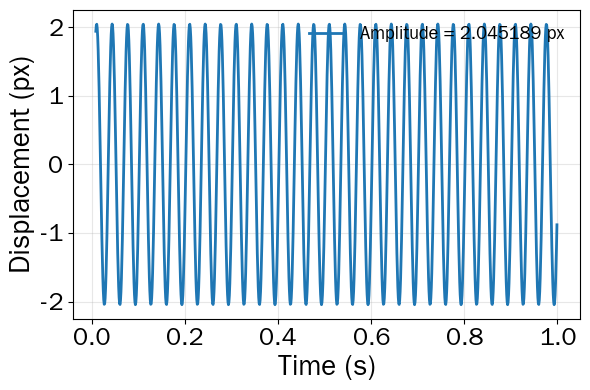

3DFIT初始频率=29.547739 Hz
3DFIT连续拟合频率=30.000465 Hz
最小位移=-2.045190 px
最大位移=2.045189 px
振幅（峰峰值/2）=2.045189 px
时间—位移图已保存：/home/ning/zd/results_222_30hz_inline_displacement/3dfit_displacement_30hz_inline_only.png


In [3]:
# 3DFIT时间—位移曲线：可从空内核独立运行
from pathlib import Path
import json
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from IPython.display import display

root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p/"data/30hz-20.hdf5").exists()), None)
if root is None:
    raise FileNotFoundError("找不到data/30hz-20.hdf5")
data_path = root/"data/30hz-20.hdf5"
out_dir = root/"results_222_30hz_inline_displacement"
out_dir.mkdir(exist_ok=True)

# 读取事件并使用原3DFIT的闭区间ROI与0–1 s时间范围。
with h5py.File(data_path, "r") as handle:
    raw = handle["CD/events"][:]
x_all = raw["x"].astype(float)
y_all = raw["y"].astype(float)
t_all = raw["t"].astype(float)*1e-6
keep = ((x_all >= 100) & (x_all <= 600) &
        (y_all >= 420) & (y_all <= 460) &
        (t_all >= 0.0) & (t_all <= 1.0))
x_raw, y_raw, t_raw = x_all[keep], y_all[keep], t_all[keep]
if len(t_raw) < 100:
    raise ValueError("3DFIT ROI内事件不足100个")

# group_size=800；当前ROI宽度小于800，因此形成一个空间组。
group_x_min = float(x_raw.min())
group_keep = (x_raw >= group_x_min) & (x_raw < group_x_min+800)
x_raw, y_raw, t_raw = x_raw[group_keep], y_raw[group_keep], t_raw[group_keep]
x_mean, y_mean = float(np.mean(x_raw)), float(np.mean(y_raw))
time_origin = float(t_raw.min())
x = x_raw-x_mean
y = y_raw-y_mean
t = t_raw-time_origin

# 原实现：在1–300 Hz之间取200个候选频率，以y相关强度最大值初始化。
frequency_grid = np.linspace(1, 300, 200)
y_centered = y-np.mean(y)
frequency_power = np.asarray([
    abs(np.sum(y_centered*np.exp(-1j*2*np.pi*frequency*t)))
    for frequency in frequency_grid
])
initial_frequency = float(frequency_grid[np.argmax(frequency_power)])
initial_parameters = [0.0, 1.0, np.ptp(y)/2,
                      initial_frequency, 0.0, 0.1, 0.0]

# 连续隐式曲面：A*x+B*y+C*exp(-lambda*t)*sin(2*pi*f*t+phi)+D=0。
def objective(parameters):
    A, B, C, frequency, phase, decay, offset = parameters
    vibration = (C*np.exp(-decay*t)*
                 np.sin(2*np.pi*frequency*t+phase))
    residual = A*x+B*y+vibration+offset
    normal_penalty = 1e6*(np.sqrt(A*A+B*B)-1.0)**2
    return np.mean(residual**2)+normal_penalty

optimization = minimize(
    objective, initial_parameters, method="L-BFGS-B",
    bounds=[(-1, 1), (-1, 1), (0, None), (1, 500),
            (-np.pi, np.pi), (0, 10), (None, None)])
if not optimization.success:
    raise RuntimeError(f"3DFIT优化失败：{optimization.message}")

# 与原实现一致，对A、B、C、D按空间法向长度归一化。
parameters = optimization.x.copy()
normal_norm = float(np.hypot(parameters[0], parameters[1]))
if normal_norm <= 1e-9:
    raise RuntimeError("3DFIT空间法向长度接近零")
parameters[[0, 1, 2, 6]] /= normal_norm
A, B, C, fitted_frequency, phase, decay, offset = parameters
if abs(B) < 1e-6:
    raise RuntimeError("3DFIT拟合B接近零，不能恢复纵向位移")

# 以1 ms重建模型振动项，并根据隐式方程恢复纵向位移y=-vibration/B。
times = np.arange(float(t_raw.min()), float(t_raw.max()), 0.001)
local_times = times-time_origin
vibration = (C*np.exp(-decay*local_times)*
             np.sin(2*np.pi*fitted_frequency*local_times+phase))
displacement = -vibration/B
minimum = float(np.min(displacement))
maximum = float(np.max(displacement))
amplitude = float(np.ptp(displacement)/2)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(times, displacement, lw=2, color="tab:blue",
        label=f"Amplitude = {amplitude:.6f} px")
ax.set_xlabel("Time (s)", fontsize=20)
ax.set_ylabel("Displacement (px)", fontsize=20)
ax.tick_params(axis="both", labelsize=18)
ax.grid(alpha=0.3)
ax.legend(frameon=False, fontsize=13, loc="upper right")
fig.tight_layout()
image_path = out_dir/"3dfit_displacement_30hz_inline_only.png"
fig.savefig(image_path, dpi=300, bbox_inches="tight")
display(fig)
plt.close(fig)

result = {
    "initial_frequency_hz": initial_frequency,
    "fitted_frequency_hz": float(fitted_frequency),
    "minimum_px": minimum, "maximum_px": maximum,
    "peak_to_peak_px": maximum-minimum,
    "amplitude_half_peak_to_peak_px": amplitude,
    "decay_per_s": float(decay),
    "fitted_parameters": [float(value) for value in parameters],
    "samples": int(len(displacement)), "dt_s": 0.001,
    "image": str(image_path),
}
np.savez(out_dir/"3dfit_displacement_30hz_inline_only.npz",
         times=times, displacement=displacement)
(out_dir/"3dfit_displacement_inline_only_summary.json").write_text(
    json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8")

print(f"3DFIT初始频率={initial_frequency:.6f} Hz")
print(f"3DFIT连续拟合频率={fitted_frequency:.6f} Hz")
print(f"最小位移={minimum:.6f} px")
print(f"最大位移={maximum:.6f} px")
print(f"振幅（峰峰值/2）={amplitude:.6f} px")
print(f"时间—位移图已保存：{image_path}")


## GPE方法和ECT方法的钢尺数据频谱复现


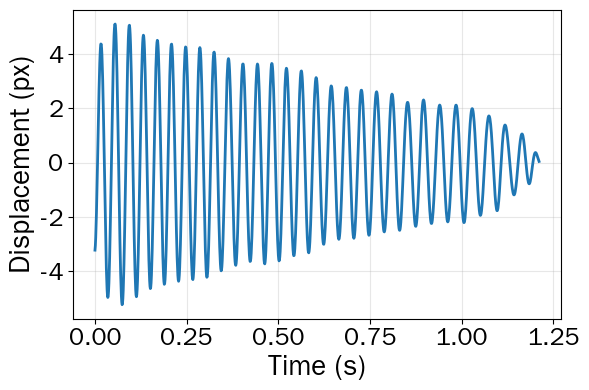

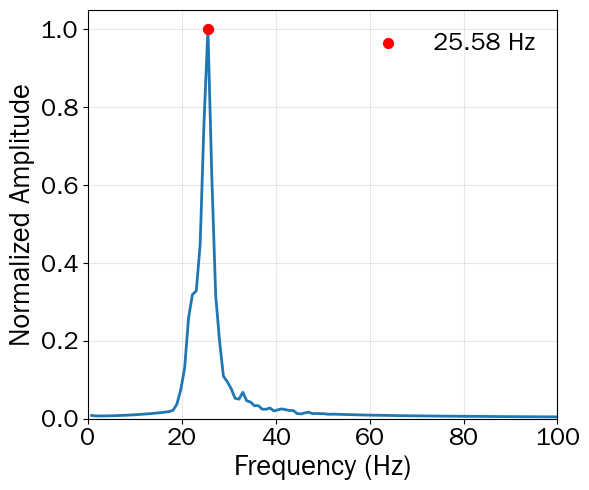

========== 修正后的Gabor相位法 ==========
主频：25.577558 Hz
未标定半峰峰值振幅：10.338631 px
标定系数：0.500
最小位移：-5.227204 px
最大位移：5.111427 px
振幅（峰峰值/2）：5.169316 px


In [4]:
# Gabor
from pathlib import Path
import h5py
import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.signal import butter, filtfilt, detrend

root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "data/zdbiaochi.hdf5").exists()), None)
if root is None:
    raise FileNotFoundError("找不到 data/zdbiaochi.hdf5")

data_path = root / "data/zdbiaochi.hdf5"
roi = (300, 400, 500, 600)  # x1, y1, x2, y2；与第二个方法为同一物理ROI
frame_dt = 0.001
gabor_wavelength = 20.0
phase_scale = 0.5             # 当前钢尺实验的幅值标定系数
lowcut, highcut = 20.0, 40.0

# ---------- 读取同一ROI的事件 ----------
with h5py.File(data_path, "r") as handle:
    raw = handle["CD/events"][:]

x1, y1, x2, y2 = roi
x_all = raw["x"].astype(np.int32)
y_all = raw["y"].astype(np.int32)
t_all = raw["t"].astype(np.float64) * 1e-6
p_all = raw["p"].astype(np.int8)
selected = ((x_all >= x1) & (x_all < x2) &
            (y_all >= y1) & (y_all < y2))
x = x_all[selected] - x1
y = y_all[selected] - y1
t = t_all[selected]
p = p_all[selected]
del raw, x_all, y_all, t_all, p_all, selected

order = np.argsort(t)
x, y, t, p = x[order], y[order], t[order], p[order]
t0 = float(t.min())
frame_id = ((t - t0) / frame_dt).astype(np.int64)
frame_count = int(frame_id.max()) + 1
height, width = y2 - y1, x2 - x1

# ---------- 复Gabor核 ----------
sigma = 0.56 * gabor_wavelength
real_kernel = cv2.getGaborKernel(
    (41, 41), sigma, np.pi / 2, gabor_wavelength,
    0.5, 0, ktype=cv2.CV_32F)
imag_kernel = cv2.getGaborKernel(
    (41, 41), sigma, np.pi / 2, gabor_wavelength,
    0.5, np.pi / 2, ktype=cv2.CV_32F)

# ---------- 逐帧响应和相邻帧局部相位增量 ----------
phase_increment = []
increment_times = []
previous_response = None
for k in range(frame_count):
    begin = int(np.searchsorted(frame_id, k, side="left"))
    end = int(np.searchsorted(frame_id, k, side="right"))
    if end - begin < 5:
        previous_response = None
        continue

    frame = np.zeros((height, width), dtype=np.float32)
    signed_polarity = 2.0 * p[begin:end].astype(np.float32) - 1.0
    np.add.at(frame, (y[begin:end], x[begin:end]), signed_polarity)
    frame = cv2.GaussianBlur(frame, (5, 5), 0)

    response = (
        cv2.filter2D(frame, cv2.CV_32F, real_kernel) +
        1j * cv2.filter2D(frame, cv2.CV_32F, imag_kernel)
    )

    if previous_response is not None:
        # angle(R_k * conj(R_{k-1}))给出每个像素的时间相位增量。
        local_increment = np.angle(response * np.conj(previous_response))
        local_weight = np.sqrt(
            np.abs(response) * np.abs(previous_response))
        reliable = local_weight >= 0.25 * np.max(local_weight)
        weighted_increment = np.sum(
            local_increment[reliable] * local_weight[reliable]
        ) / (np.sum(local_weight[reliable]) + 1e-12)
        phase_increment.append(weighted_increment)
        increment_times.append(t0 + (k + 0.5) * frame_dt)

    previous_response = response

phase_increment = np.asarray(phase_increment, dtype=np.float64)
increment_times = np.asarray(increment_times, dtype=np.float64)
if len(phase_increment) < 20:
    raise RuntimeError("有效Gabor相位增量样本不足")

# 有效帧在当前数据中连续；若有缺帧，先插值到1 ms均匀时间轴。
if not np.allclose(np.diff(increment_times), frame_dt,
                   rtol=1e-5, atol=1e-10):
    uniform_times = np.arange(
        increment_times[0], increment_times[-1] + 0.5 * frame_dt, frame_dt)
    phase_increment = np.interp(
        uniform_times, increment_times, phase_increment)
    increment_times = uniform_times

phase_increment -= np.mean(phase_increment)
sampling_rate = 1.0 / frame_dt
b, a = butter(
    4, [lowcut / (0.5 * sampling_rate),
        highcut / (0.5 * sampling_rate)], btype="band")
filtered_increment = filtfilt(b, a, phase_increment)

# 相位增量 → 像素增量 → 累积位移。
uncalibrated_displacement = detrend(np.cumsum(
    filtered_increment * gabor_wavelength / (2.0 * np.pi)))
uncalibrated_displacement = gaussian_filter1d(
    uncalibrated_displacement, sigma=1.0)
displacement = phase_scale * uncalibrated_displacement
displacement -= np.mean(displacement)
times = increment_times - increment_times[0]

# ---------- 振幅与正频率频谱 ----------
minimum = float(np.min(displacement))
maximum = float(np.max(displacement))
amplitude = float((maximum - minimum) / 2.0)
uncalibrated_amplitude = float(np.ptp(uncalibrated_displacement) / 2.0)

frequencies = np.fft.rfftfreq(len(displacement), d=frame_dt)
magnitude = np.abs(np.fft.rfft(displacement - np.mean(displacement)))
positive = frequencies > 0
frequencies = frequencies[positive]
magnitude = magnitude[positive]
normalized_spectrum = magnitude / (np.max(magnitude) + 1e-12)
peak_index = int(np.argmax(normalized_spectrum))
peak_hz = float(frequencies[peak_index])

# ---------- 时间—位移图 ----------
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(times, displacement, lw=2, color="tab:blue")
ax.set_xlabel("Time (s)", fontsize=20)
ax.set_ylabel("Displacement (px)", fontsize=20)
ax.grid(alpha=0.3)
ax.tick_params(axis="both", labelsize=18)
fig.tight_layout()
plt.show()

# ---------- 频谱图 ----------
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(frequencies, normalized_spectrum, lw=2, color="tab:blue")
ax.scatter(peak_hz, normalized_spectrum[peak_index], color="red", s=50,
           zorder=3, label=f"{peak_hz:.2f} Hz")
ax.set_xlabel("Frequency (Hz)", fontsize=20)
ax.set_ylabel("Normalized Amplitude", fontsize=20)
ax.set_xlim(0, 100)
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3)
ax.tick_params(axis="both", labelsize=18)
ax.legend(frameon=False, fontsize=18, loc="upper right")
fig.tight_layout()
plt.show()

corrected_gabor_output = {
    "method": "local Gabor phase increment",
    "roi_xyxy": roi,
    "frame_dt_s": frame_dt,
    "gabor_wavelength_px": gabor_wavelength,
    "phase_scale": phase_scale,
    "frequency_hz": peak_hz,
    "uncalibrated_amplitude_px": uncalibrated_amplitude,
    "amplitude_px": amplitude,
    "minimum_px": minimum,
    "maximum_px": maximum,
    "times": times,
    "displacement": displacement,
    "frequencies": frequencies,
    "normalized_spectrum": normalized_spectrum,
}

print("========== 修正后的Gabor相位法 ==========")
print(f"主频：{peak_hz:.6f} Hz")
print(f"未标定半峰峰值振幅：{uncalibrated_amplitude:.6f} px")
print(f"标定系数：{phase_scale:.3f}")
print(f"最小位移：{minimum:.6f} px")
print(f"最大位移：{maximum:.6f} px")
print(f"振幅（峰峰值/2）：{amplitude:.6f} px")


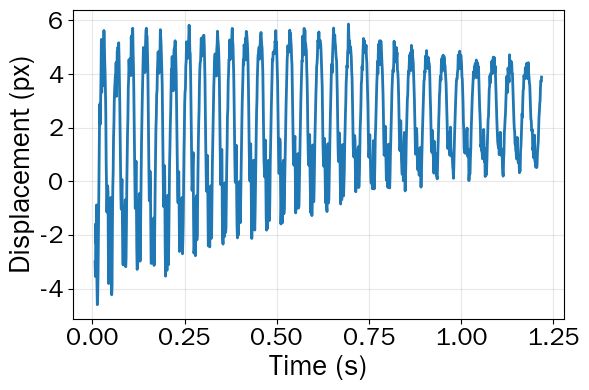

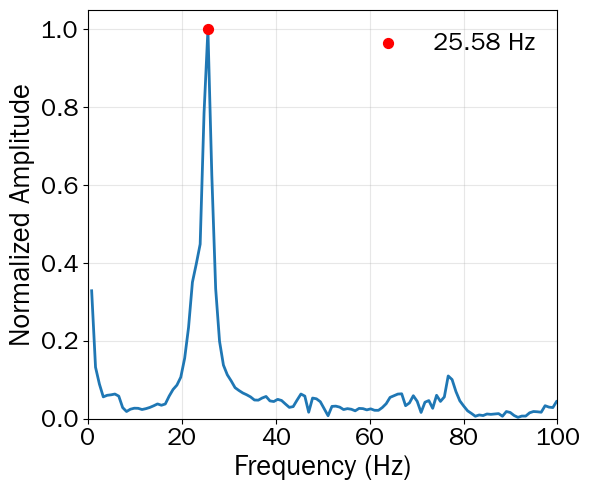

[Marker tracking] Estimated frequency: 25.58 Hz


In [5]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

# =========================================================
# 1. 事件数据读取
# =========================================================
def load_events(file_path):
    with h5py.File(file_path, 'r') as f:
        if 'CD' in f and 'events' in f['CD']:
            e = f['CD/events'][:]
            return {
                'x': e['x'].astype(float),
                'y': e['y'].astype(float),
                't': e['t'].astype(float) * 1e-6,  # us → s
                'p': e['p'].astype(float)
            }
    raise ValueError("Invalid HDF5 format")


# =========================================================
# 2. Marker tracking（论文 2.2：质心平均）
# =========================================================
def marker_tracking_frequency(events, roi, window_dt=1e-3, axis='y'):
    x, y, t = events['x'], events['y'], events['t']

    mask = (
        (x >= roi[0]) & (x <= roi[1]) &
        (y >= roi[2]) & (y <= roi[3])
    )
    x, y, t = x[mask], y[mask], t[mask]

    t_start, t_end = t.min(), t.max()
    bins = np.arange(t_start, t_end, window_dt)

    pos_list = []
    time_list = []

    for i in range(len(bins) - 1):
        idx = (t >= bins[i]) & (t < bins[i + 1])
        if np.sum(idx) < 5:
            continue

        pos = np.mean(y[idx]) if axis == 'y' else np.mean(x[idx])
        pos_list.append(pos)
        time_list.append(0.5 * (bins[i] + bins[i + 1]))

    return np.array(time_list), np.array(pos_list)


# =========================================================
# 3. FFT + 0–1 归一化
# =========================================================
def estimate_frequency_fft(t, signal):
    dt = np.mean(np.diff(t))
    N = len(signal)

    # 先去均值以消除直流分量，再做单边FFT。
    fft_val = np.fft.rfft(signal - np.mean(signal))
    freq = np.fft.rfftfreq(N, dt)
    amp = np.abs(fft_val)

    # 完全删除0 Hz，只保留严格大于0 Hz的频率点。
    positive = freq > 0
    freq = freq[positive]
    amp = amp[positive]
    if len(freq) == 0 or np.max(amp) <= 0:
        raise ValueError("没有可用于频谱分析的正频率分量")

    amp = amp / np.max(amp)  # 正频率范围内归一化到0–1
    peak_idx = int(np.argmax(amp))
    peak_freq = float(freq[peak_idx])

    return freq, amp, peak_freq, peak_idx


# =========================================================
# 4. 主流程 + 可视化
# =========================================================
def run_marker_tracking(file_path):
    # ---------- 可视化参数 ----------
    grid_alpha = 0.3
    label_fontsize = 20
    tick_fontsize = 18

    # ---------- 参数 ----------
    roi = (300, 500, 400, 600)   # 根据你的 marker 调整
    window_dt = 1e-3
    ref_y = 510                  # 静止参考位置

    events = load_events(file_path)

    t_m, pos = marker_tracking_frequency(
        events, roi, window_dt, axis='y'
    )

    disp = pos - ref_y

    freq, amp, f_peak, peak_idx = estimate_frequency_fft(t_m, disp)

    # =========================
    # 图1：位移时间序列
    # =========================
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(t_m, disp, lw=2, color="tab:blue")
    ax.set_xlabel("Time (s)", fontsize=20)
    ax.set_ylabel("Displacement (px)", fontsize=20)
    ax.grid(alpha=0.3)
    ax.tick_params(axis="both", labelsize=18)
    fig.tight_layout()
    fig.savefig("gangchi_domain.png", dpi=300, bbox_inches="tight")
    plt.show()

    # =========================
    # 图2：归一化频谱与主频标注
    # =========================
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.plot(freq, amp, lw=2, color="tab:blue")
    ax.scatter(freq[peak_idx], amp[peak_idx], color="red", s=50,
               zorder=3, label=f"{f_peak:.2f} Hz")
    ax.set_xlabel("Frequency (Hz)", fontsize=20)
    ax.set_ylabel("Normalized Amplitude", fontsize=20)
    ax.set_xlim(0, 100)  # 坐标轴显示0–100 Hz；频谱数据仍不包含0 Hz分量
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.3)
    ax.tick_params(axis="both", labelsize=18)
    ax.legend(frameon=False, fontsize=18, loc="upper right")
    fig.tight_layout()
    # fig.savefig("gangchi_pinpu.png", dpi=300, bbox_inches="tight")
    plt.show()

    print(f"[Marker tracking] Estimated frequency: {f_peak:.2f} Hz")


# =========================================================
# 5. 入口
# =========================================================
if __name__ == "__main__":
    run_marker_tracking("./data/zdbiaochi.hdf5")
